# 속도 역기구학


In [1]:
import math
import matplotlib.pyplot as plt

dictionary를 XY 좌표평면에 표시하는 함수


In [2]:
def plot_positions(positions, show_robot=False, robot_radius_m=0.089):
    points = []
    for name, coordinate in positions.items():
        x, y = coordinate
        if not (math.isfinite(x) and math.isfinite(y)):
            raise ValueError(f"{name}: 좌표는 유한한 숫자여야 합니다")
        points.append((name, x, y))

    if show_robot and (not math.isfinite(robot_radius_m) or robot_radius_m <= 0):
        raise ValueError("robot_radius_m은 양수여야 합니다")

    fig, ax = plt.subplots(figsize=(6, 6))
    for name, x, y in points:
        ax.scatter(x, y, s=80)
        ax.annotate(
            f"{name} ({x:.4f}, {y:.4f})", (x, y),
            xytext=(6, 8), textcoords="offset points",
        )

    if show_robot:
        # 지름 178 mm의 단순 기준 원. 실제 캡처 홈은 생략.
        ax.add_patch(plt.Circle(
            (0, 0), robot_radius_m, fill=False,
            edgecolor="black", linewidth=1.5, label="Robot outline circle",
        ))
        ax.legend()

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    # 입력 점이 멀리 있어도 잘리지 않도록 모든 점을 포함하는 범위를 사용.
    extent = max([0.01] + [max(abs(x), abs(y)) for _, x, y in points])
    if show_robot:
        extent = max(extent, robot_radius_m)
    limit = extent * 1.25
    ax.set(
        xlabel="X [m]", ylabel="Y [m]",
        xlim=(-limit, limit), ylim=(-limit, limit), title="XY positions",
    )
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    plt.show()
    return fig, ax

각 위치에 각도 방향의 벡터 표시하는 함수


In [3]:
def plot_vectors(positions, angles_rad, signs=None, length_m=0.025, show_robot=False):
    """+X 오른쪽, +Y 앞쪽. signs 지정 시 모터 +명령의 구동 방향 표시."""
    # signs를 생략하면 기하학적 방향만 표시. 모터 방향은 MOTOR_SIGN을 전달.
    if signs is not None:
        for name in positions:
            if signs[name] not in (-1, +1):
                raise ValueError(f"{name}: sign은 +1 또는 -1이어야 합니다")
    fig, ax = plt.subplots(figsize=(6, 6))

    for name, (x, y) in positions.items():
        angle = angles_rad[name]
        # 기하학적 방향 각도는 유지하고 부호만 적용한다.
        # +1: 기존 방향, -1: 반대 방향. 향후 IK 명령에도 같은 부호를 곱한다.
        sign = 1 if signs is None else signs[name]
        dx = sign * length_m * math.cos(angle)
        dy = sign * length_m * math.sin(angle)
        ax.scatter(x, y, color="tab:blue", s=30)
        ax.quiver(
            x, y, dx, dy,
            angles="xy", scale_units="xy", scale=1,
            color="tab:blue", width=0.006,
        )
        ax.annotate(name, (x, y), xytext=(5, 7), textcoords="offset points")

    if show_robot:
        ax.add_patch(plt.Circle((0, 0), 0.089, fill=False, color="black"))

    extent = max([0.01] + [max(abs(x), abs(y)) for x, y in positions.values()])
    limit = max(extent + abs(length_m), 0.089 if show_robot else 0) * 1.2
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit),
           xlabel="X [m] - Right (+)", ylabel="Y [m] - Front (+)",
           title="Motor +command directions" if signs is not None else "Geometric drive directions")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    plt.show()

모터


In [4]:
MOTOR_ORDER = ("fr", "rr", "rl", "fl")

# fr: 35°, rr: -45°, rl: -135°, fl: 145°
# 앞쪽(+Y) 기준으로는 앞 모터가 좌우 55° 기울어짐.
MOTOR_ANGLE_RAD = {
    "fr": math.radians(35.0),
    "rr": math.radians(-45.0),
    "rl": math.radians(-135.0),
    "fl": math.radians(145.0),
}

MOTOR_ANGLE_RAD  # 단위: rad

{'fr': 0.6108652381980153,
 'rr': -0.7853981633974483,
 'rl': -2.356194490192345,
 'fl': 2.530727415391778}

구동 방향


In [5]:
# 구동 방향 각도 = 모터 축 각도 + 90°
# fr: 125°, rr: 45°, rl: -45°, fl: 235°
DRIVE_ANGLE_RAD = {
    motor: angle + math.pi / 2 for motor, angle in MOTOR_ANGLE_RAD.items()
}

DRIVE_ANGLE_RAD  # 단위: rad

{'fr': 2.181661564992912,
 'rr': 0.7853981633974483,
 'rl': -0.7853981633974483,
 'fl': 4.101523742186675}

In [6]:
# 반지름 25 mm = 0.025 m
WHEEL_RADIUS_M = {
    "fr": 0.025,
    "rr": 0.025,
    "rl": 0.025,
    "fl": 0.025,
}

# 바퀴 위치
WHEEL_POSITION_M = {
    "fr": (0.0666044692, 0.0466364454),
    "rr": (0.0574939788, -0.0574939788),
    "rl": (-0.0574939788, -0.0574939788),
    "fl": (-0.0666044692, 0.0466364453),
}

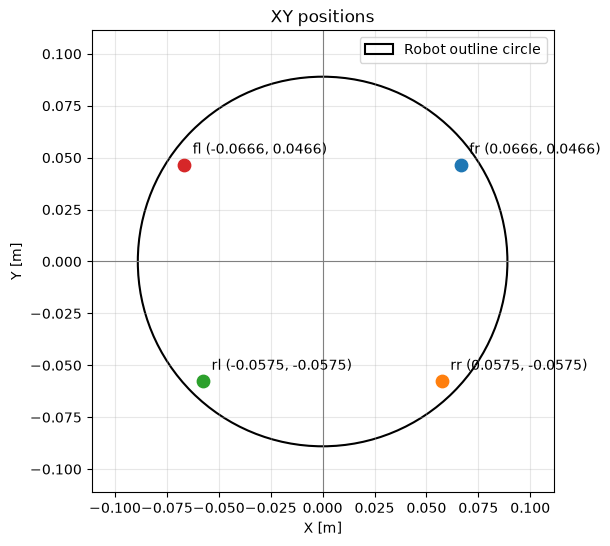

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'XY positions'}, xlabel='X [m]', ylabel='Y [m]'>)

In [7]:
plot_positions(WHEEL_POSITION_M, show_robot=True)

모터 구동 방향


In [8]:
MOTOR_SIGN = {
    "fr": -1,
    "rr": -1,
    "rl": -1,
    "fl": -1,
}

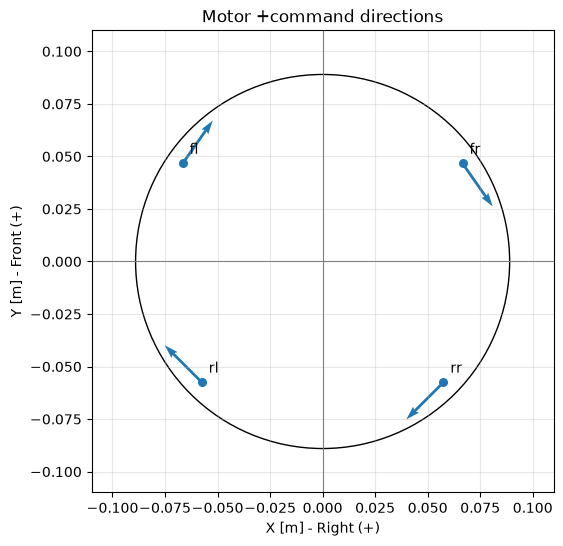

In [9]:
plot_vectors(WHEEL_POSITION_M, DRIVE_ANGLE_RAD, signs=MOTOR_SIGN, show_robot=True)

---


목표로 하는 로봇의 전진 속도 [m/s]


$$
\mathbf{v}=
\begin{bmatrix}V_X\\V_Y\end{bmatrix}
=
\begin{bmatrix}0\\1\end{bmatrix}
$$


① fr 각속도 구해보자


In [10]:
vx, vy = 0.0, 1.0

fr의 구동 방향 각도 [rad]


In [11]:
beta = DRIVE_ANGLE_RAD["fr"]
beta

2.181661564992912

$$
\begin{bmatrix}
v_{\parallel}\\
v_{\perp}
\end{bmatrix}
=
\begin{bmatrix}
\cos125^\circ & \sin125^\circ\\
-\sin125^\circ & \cos125^\circ
\end{bmatrix}
\begin{bmatrix}0\\1\end{bmatrix}
$$


- $v_{\parallel}$: 바퀴가 구동하는 방향의 속도
- $v_{\perp}$: 작은 롤러가 허용하는 방향의 속도


In [12]:
math.cos(beta)

-0.5735764363510462

In [13]:
math.sin(beta)

0.8191520442889917

In [14]:
v_parallel = math.cos(beta) * vx + math.sin(beta) * vy
v_parallel

0.8191520442889917

$$
v_{\parallel}
=(-0.5736)\times0+(+0.8192)\times1
={+0.8192\ \text{m/s}}
$$


바퀴가 구동하는 방향의 속도가 +0.8192 m/s 다!

---


옴니휠 반지름으로 나눠 회전 속도 구하기

$R=0.025$ m


In [15]:
WHEEL_RADIUS_M["fr"]

0.025

In [16]:
omega = v_parallel / WHEEL_RADIUS_M["fr"]
omega

32.76608177155966

각속도 $\omega = +32.77$ rad/s


---


모터 부호 보정


In [17]:
command = MOTOR_SIGN["fr"] * omega
command

-32.76608177155966

**목표 회전 속도**: −32.77 rad/s

---


② rr 구해보자


In [18]:
vx, vy = 0.0, 1.0

beta = DRIVE_ANGLE_RAD["rr"]

v_parallel = math.cos(beta) * vx + math.sin(beta) * vy

omega = v_parallel / WHEEL_RADIUS_M["rr"]
command = MOTOR_SIGN["rr"] * omega

print("휠 구동 방향 속도:", v_parallel, "m/s")
print("모터 명령:", command, "rad/s")

휠 구동 방향 속도: 0.7071067811865475 m/s
모터 명령: -28.2842712474619 rad/s


### 결론

`power = 100 * 목표_각속도 / 최대파워에서의_각속도`

전진 1 m/s의 휠 목표:

- fr = +32.77 rad/s → +43
- rr = +28.28 rad/s → +37
- rl = −28.28 rad/s → −37
- fl = −32.77 rad/s → −43


---

### 자코비안을 통해 한번에 구해보자

$$
\begin{bmatrix}
\omega_{fr}\\
\omega_{rr}\\
\omega_{rl}\\
\omega_{fl}
\end{bmatrix}
=
\underbrace{
\begin{bmatrix}
\cos125^\circ/0.025 & \sin125^\circ/0.025\\
\cos45^\circ/0.025 & \sin45^\circ/0.025\\
\cos(-45^\circ)/0.025 & \sin(-45^\circ)/0.025\\
\cos235^\circ/0.025 & \sin235^\circ/0.025
\end{bmatrix}}_{J}
\begin{bmatrix}V_X\\V_Y\end{bmatrix}
$$


$$
J\approx
\begin{bmatrix}
-22.943 & +32.766\\
+28.284 & +28.284\\
+28.284 & -28.284\\
-22.943 & -32.766
\end{bmatrix}
$$


In [19]:
import numpy as np

J = np.array([
    [
        math.cos(DRIVE_ANGLE_RAD[motor]) / WHEEL_RADIUS_M[motor],
        math.sin(DRIVE_ANGLE_RAD[motor]) / WHEEL_RADIUS_M[motor],
    ]
    for motor in MOTOR_ORDER
])
J

array([[-22.94305745,  32.76608177],
       [ 28.28427125,  28.28427125],
       [ 28.28427125, -28.28427125],
       [-22.94305745, -32.76608177]])

- 행: fr, rr, rl, fl
- 열: X 오른쪽, Y 앞쪽


In [20]:
velocity = np.array([0.0, 1.0])  # 전진 1 m/s

wheel_rad_s = J @ velocity
motor_rad_s = wheel_rad_s * np.array([
    MOTOR_SIGN[motor] for motor in MOTOR_ORDER
])

motor_rad_s

array([-32.76608177, -28.28427125,  28.28427125,  32.76608177])